# LIBERO-PRO, Object suite: the released policy, and the same policy steered by an oracle plan
**VLA direction** · LIBERO-PRO (arXiv 2510.03827) · released starVLA checkpoint `Qwen3-VL-PI-LIBERO-4in1` · 12 Nov 2026 · the first numbers on an official perturbed benchmark

- **The question:** on the benchmark other papers report, how far does the released policy fall when the target is moved or another object is asked for, and how much of that would an action head that obeys a plan recover if the plan were right?
- **Real:** the benchmark's scenes, start states and goal checks; the released policy; the action head trained with counterfactual plans on 11 Nov; all rollouts. That head saw six of the ten LIBERO-Object tasks: the bbq sauce, butter, chocolate pudding and orange juice were never targets in its training. A head trained on all ten tasks is added as a third column when its run is complete.
- **ORACLE:** the plan given to the second policy (object position from the simulator plus the average grasp point of the demonstrations). Its column is an upper bound for a plan head, not a result of a method.
- **Protocol:** both policies saw only standard LIBERO demonstrations. 10 tasks × 20 start states (0–19) per perturbation; the benchmark's papers use 50. A rollout counts when the benchmark's goal check holds. One run, one seed.

```text
(1) the two perturbations of one task                      real (benchmark files)
        ↓
(2) solved rollouts: released policy / oracle-plan policy  real rollouts; the plan is ORACLE
        ↓
(3) per task, and what happened to the named object        real
        ↓
(4) numbers other papers report on the same benchmark      quoted, not re-run
```

<sub>To re-run on the A6000 server: `envs/server/setup_libero_pro.sh` (CPU), then `scripts/eval/run_libero_pro_gpu.sh` through the GPU queue with `NAME=released` and with `NAME=oracle_plan_s2 ADAPTER=s2_actions PLAN=oracle` (ten-task head: `NAME=oracle_plan ADAPTER=s4_actions10 PLAN=oracle`), then execute this notebook.</sub>

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance_vla").is_dir())
sys.path.insert(0, str(ROOT))
from affordance_vla.sim.rollout_log import load_rollout_log
from report import libero_pro_helpers as L
from report import vla_pipeline_demo_helpers as H

set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 120)

PRO = ROOT / "runs" / "libero_pro"
RELEASED, ORACLE = "released policy, no plan", "action head from six tasks + ORACLE plan"
TEN = "action head from ten tasks + ORACLE plan"
FOLDERS = {RELEASED: PRO / "released", ORACLE: PRO / "oracle_plan_s2"}
if all(len(list((PRO / "oracle_plan" / suite).glob("task*_ep*.npz"))) >= 200 for suite in L.SUITES.values()):
    FOLDERS[TEN] = PRO / "oracle_plan"
runs = {name: {suite: L.load_suite(folder, suite) for suite in L.SUITES.values()} for name, folder in FOLDERS.items()}
print({name: {suite: len(logs) for suite, logs in run.items()} for name, run in runs.items()})

{'released policy, no plan': {'libero_object_swap': 200, 'libero_object_task': 200}, 'action head from six tasks + ORACLE plan': {'libero_object_swap': 200, 'libero_object_task': 200}}


## 1 · The two perturbations
**This step:** the same task, "pick up the salad dressing and place it in the basket", as LIBERO has it and as LIBERO-PRO changes it. The position perturbation lets the target trade places with another object; the instruction stays. The task perturbation leaves the scene and asks for another object of it.

**Status:** real; the frames are the first camera image of a rollout. LIBERO takes a task's instruction from its file name, which the task perturbation does not change: the new object is only named inside the task file. The instruction used here is the trained wording with that object put in (`affordance_vla/sim/benchmark_text.py`).

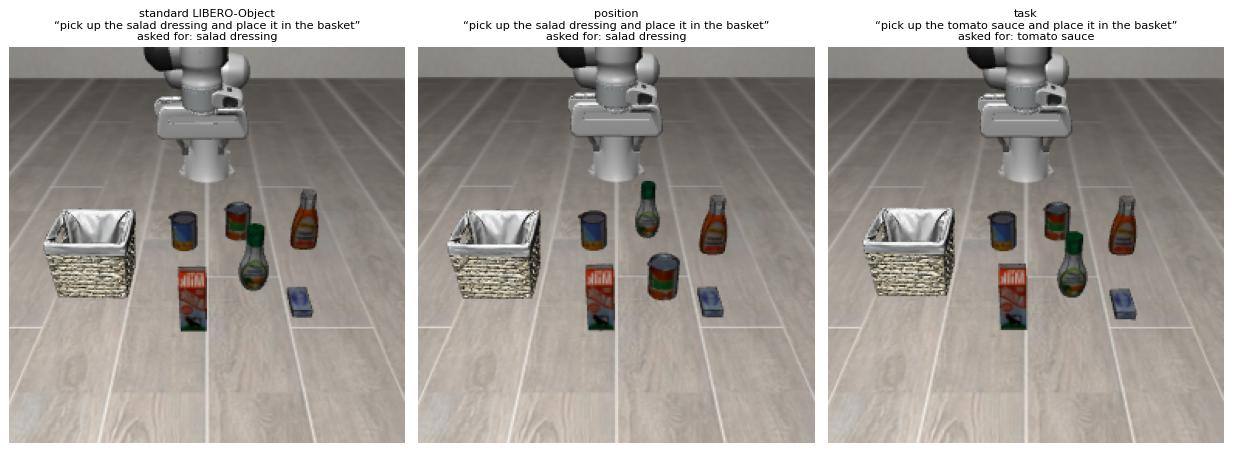

In [2]:
TASK = 2   # the salad dressing task in both suites
standard = load_rollout_log(ROOT / "runs" / "plan_following" / "demos"
                            / "pick_up_the_salad_dressing_and_place_it_in_the_basket_demo0.npz")
shown = {label.split(":")[0]: load_rollout_log(PRO / "released" / suite / f"task{TASK}_ep0.npz")
         for label, suite in L.SUITES.items()}
fig = L.starts_figure(standard, shown)
plt.show()

## 2 · Solved rollouts
**This step:** every task of the suite from 20 start states, under each perturbation, for the two policies.

**Status:** real rollouts. The second column is given the ORACLE plan at every query, so it shows what the action head can do when the plan is right.

In [3]:
display(L.score_table(runs))

,"released policy, no plan",action head from six tasks + ORACLE plan
position: the target swaps places with another object,0 / 200 = 0.00,164 / 200 = 0.82
task: the instruction and the goal name another object,20 / 200 = 0.10,136 / 200 = 0.68


## 3 · Per task, and what happened to the named object
**This step:** the same counts for each task, then the outcome of every rollout judged by what the gripper held: the named object was delivered (`success`), another object was grasped first (`wrong object`), nothing was held (`no grasp`), or the named object was held but did not end in the basket (`not delivered`).

**Status:** real. For the policy with a plan, the last table splits its rollouts by how far they got.

In [4]:
for label, suite in L.SUITES.items():
    print(label)
    display(L.per_task_table(runs, suite))

position: the target swaps places with another object


,instruction given,"released policy, no plan",action head from six tasks + ORACLE plan
task,,,
0,pick up the alphabet soup and place it in the basket,0 / 20,17 / 20
1,pick up the cream cheese and place it in the basket,0 / 20,20 / 20
2,pick up the salad dressing and place it in the basket,0 / 20,12 / 20
3,pick up the bbq sauce and place it in the basket,0 / 20,20 / 20
4,pick up the ketchup and place it in the basket,0 / 20,11 / 20
5,pick up the tomato sauce and place it in the basket,0 / 20,20 / 20
6,pick up the butter and place it in the basket,0 / 20,20 / 20
7,pick up the milk and place it in the basket,0 / 20,20 / 20
8,pick up the chocolate pudding and place it in the basket,0 / 20,20 / 20


task: the instruction and the goal name another object


,instruction given,"released policy, no plan",action head from six tasks + ORACLE plan
task,,,
0,pick up the cream cheese and place it in the basket,0 / 20,19 / 20
1,pick up the alphabet soup and place it in the basket,20 / 20,20 / 20
2,pick up the tomato sauce and place it in the basket,0 / 20,13 / 20
3,pick up the ketchup and place it in the basket,0 / 20,6 / 20
4,pick up the milk and place it in the basket,0 / 20,3 / 20
5,pick up the bbq sauce and place it in the basket,0 / 20,12 / 20
6,pick up the orange juice and place it in the basket,0 / 20,4 / 20
7,pick up the butter and place it in the basket,0 / 20,20 / 20
8,pick up the salad dressing and place it in the basket,0 / 20,19 / 20


In [5]:
for label, suite in L.SUITES.items():
    print(label)
    display(L.outcome_counts(runs, suite))
display(pd.DataFrame({f"{name.split(' +')[0]}: {label.split(':')[0]}": L.stage_counts(folder, suite)
                      for name, folder in FOLDERS.items() if name != RELEASED for label, suite in L.SUITES.items()}))

position: the target swaps places with another object


,wrong object,no grasp,rollouts,success,not delivered
"released policy, no plan",195,5,200,0,0
action head from six tasks + ORACLE plan,0,17,200,164,19


task: the instruction and the goal name another object


,wrong object,success,no grasp,rollouts,not delivered
"released policy, no plan",175,20,5,200,0
action head from six tasks + ORACLE plan,0,136,28,200,36


,action head from six tasks: position,action head from six tasks: task
rollouts,200,200
gripper came within 2 cm of the planned grasp point,193,187
object knocked over before it was held,33,52
object held,183,172
object in the basket at the end,164,136
"held, then let go outside the basket",16,22
"held, still in the gripper at the end",3,14


In [6]:
SHORT = {RELEASED: "released", ORACLE: "ORACLE plan"}
clips = {f"{SHORT[name]} - {label.split(':')[0]}": load_rollout_log(FOLDERS[name] / suite / f"task{TASK}_ep0.npz")
         for label, suite in L.SUITES.items() for name in SHORT}
CLIP = ROOT / "report" / "media" / "libero_pro_object.mp4"   # tracked in git
H.render_rollout_grid(list(clips.values()), list(clips), CLIP)
Video(str(CLIP), embed=True, width=1100)

## 4 · What other papers report on LIBERO-PRO
**This step:** published numbers for the same two perturbations, on all four suites; the Object suite is the second number of each cell.

**Status:** quoted from the papers, not re-run here. They are not directly comparable with section 2: the papers use 50 trials per task, their baselines disagree with each other (three different values for π0.5 on the Object suite's position perturbation), and it is not known which instruction each of them fed under the task perturbation.

In [7]:
display(L.published_table())

,what it is,position (Spatial / Object / Goal / LIBERO-10),task (Spatial / Object / Goal / LIBERO-10)
"π0.5, as reported in the GAM paper",official checkpoint,0.20 / 0.17 / 0.38 / 0.08,0.01 / 0.01 / 0.00 / 0.01
"π0.5, as reported in the CounterAlign paper",trained on LIBERO,0.53 / 0.19 / 0.29 / 0.06,0.55 / 0.10 / 0.17 / 0.17
GAM (arXiv 2609.23863),"not a VLA; 3D detector, simulator depth",0.60 / 0.47 / 0.19 / 0.05,0.88 / 0.50 / 0.16 / 0.08
CounterAlign (arXiv 2608.21740),π0.5 + offline RL,0.60 / 0.51 / 0.41 / 0.11,0.63 / 0.26 / 0.46 / 0.29
π0.5 + Affordance Field Intervention (arXiv 2512.07472),test-time depth and GPT-4o,0.76 / 0.73 / – / –,– / – / – / –


## What to take from this

**What this run shows**
- **The released policy survives neither perturbation.** With the target moved: 0 of 200. With another object asked for: 20 of 200, all from one task in which the object asked for happens to be the one the policy takes in that layout anyway. In 370 of its 400 rollouts it grasps another object first.
- **With the right plan, the same frozen VLM solves most of them.** The action head trained with counterfactual plans, given the ORACLE plan, solves 164 of 200 (0.82) with the target moved and 136 of 200 (0.68) with another object asked for. It never grasps a wrong object, and its gripper comes within 2 cm of the planned grasp point in 193 and 187 of 200 rollouts.
- **This also holds for objects the head never trained on.** The bbq sauce, butter and chocolate pudding were never targets in its training; with the target moved it solves 20 of 20 for each. Going to a contact point is not tied to the object. The fourth new object, the orange juice, gets 4 of 20, so it is not free either.
- **What fails is the handling, not where to go.** With the target moved, 36 rollouts fail: in 17 the object is never held, in 16 it is let go outside the basket, in 3 it is still in the gripper at the end. With another object asked for, 64 fail: 28, 22 and 14. The object is knocked over before it is held in 33 and 52 rollouts. The weak objects are the tall ones: ketchup (11 and 6 of 20), orange juice (4 and 4), milk (3 of 20 when asked for).
- **The upper bound lies above what has been published for this suite.** On the Object suite other papers report 0.17–0.19 for π0.5, 0.47 for GAM, 0.51 for CounterAlign and 0.73 for π0.5 with a test-time affordance field under the position perturbation, and 0.01–0.10, 0.50 and 0.26 under the task perturbation. The oracle plan gives 0.82 and 0.68. This is room to work in, not a result: the plan is ground truth.

**What it does not show**
- **No plan is predicted here.** Everything now depends on the plan predictor; its error comes off these numbers.
- **One of four suites, 20 trials per task instead of 50, one run, one seed.**
- **The comparison with published numbers is loose.** Trials and protocol differ, the papers' own baselines disagree, and which instruction they fed under the task perturbation is not known.
- **The action head saw six of the ten tasks.** The head trained on all ten was still training when this was written.
- **Object appearance and language perturbations, and the Spatial, Goal and LIBERO-10 suites, were not run.** Those suites contain skills other than pick-and-place, for which "the contact of the next gripper event" still has to be defined.

**Next**
1. The plan predictor (in training): its contact error on these start frames, then this table again with predicted plans.
2. The ten-task action head as a third column.
3. The handling failures: tall objects that are knocked over, and the carry and release, where no counterfactual plans were used yet.
4. The other three suites, once the plan is defined for their skills.